In [1]:
import pandas as pd
import numpy as np
import statsmodels.api as sm
import matplotlib.pyplot as plt
import seaborn as sns
from sqlalchemy import create_engine

DB_USER = "postgres"
DB_PASSWORD = "zxcZXC#123"  
DB_HOST = "localhost"
DB_PORT = "5432"
DB_NAME = "retail-demand-pricing"      

engine = create_engine(f"postgresql://{DB_USER}:{DB_PASSWORD}@{DB_HOST}:{DB_PORT}/{DB_NAME}")

query = """
SELECT *
FROM retail.fact_demand;
"""

df = pd.read_sql(query, engine)
print(f"Data loaded successfully. Shape: {df.shape}")

Data loaded successfully. Shape: (50000, 47)


Data Filtering & Log Transformation

In [2]:
elasticity_df = df[
    (df["selling_price"] > 0) & 
    (df["demand_units"] > 0)
].copy()

elasticity_df["log_demand"] = np.log(elasticity_df["demand_units"])
elasticity_df["log_price"] = np.log(elasticity_df["selling_price"])

print("Log transformations generated cleanly!")
print(elasticity_df[["demand_units", "log_demand", "selling_price", "log_price"]].head())

Log transformations generated cleanly!
   demand_units  log_demand  selling_price  log_price
0         169.0    5.129899         774.11   6.651714
1         162.0    5.087596         785.91   6.666842
2         159.0    5.068904         771.50   6.648337
3         236.0    5.463832         696.87   6.546599
4         159.0    5.068904         766.00   6.641182


Overall Macro Price Elasticity Model (OLS)

In [3]:
X = elasticity_df[
    [
        "log_price",
        "discount_pct",
        "promotion_flag",
        "festival_flag"
    ]
]
X = sm.add_constant(X)
y = elasticity_df["log_demand"]

elasticity_model = sm.OLS(y, X).fit()

print(elasticity_model.summary())

overall_elasticity = elasticity_model.params["log_price"]
print(f"\n==========================================")
print(f"Estimated Overall Price Elasticity: {overall_elasticity:.4f}")
print(f"==========================================")

                            OLS Regression Results                            
Dep. Variable:             log_demand   R-squared:                       0.665
Model:                            OLS   Adj. R-squared:                  0.665
Method:                 Least Squares   F-statistic:                 2.486e+04
Date:                Sat, 17 Oct 2026   Prob (F-statistic):               0.00
Time:                        00:10:07   Log-Likelihood:                -41861.
No. Observations:               50000   AIC:                         8.373e+04
Df Residuals:                   49995   BIC:                         8.378e+04
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
                     coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------
const              9.4544      0.017    566.

Category-Level Price Elasticity Analysis

In [4]:
elasticities = []

for category, group in elasticity_df.groupby("category"):
    X_cat = group[
        [
            "log_price",
            "discount_pct",
            "promotion_flag",
            "festival_flag"
        ]
    ]
    X_cat = sm.add_constant(X_cat)
    y_cat = group["log_demand"]
    
    cat_model = sm.OLS(y_cat, X_cat).fit()
    
    elasticities.append({
        "Category": category,
        "Elasticity": cat_model.params["log_price"],
        "P-Value": cat_model.pvalues["log_price"],
        "R2": cat_model.rsquared,
        "Observations": len(group)
    })

elasticity_results = pd.DataFrame(elasticities).sort_values(by="Elasticity")
display(elasticity_results)

,Category,Elasticity,P-Value,R2,Observations
0,Electronics,0.008138,3.604869e-01,0.160396,10000
3,Personal Care,0.094519,2.221503e-48,0.164870,10000
4,Sports,0.275835,1.418482e-48,0.169820,10000
2,Home Appliances,0.302434,1.962168e-70,0.130250,10000
1,Grocery,0.574658,1.074678e-185,0.275262,10000


Elasticity Interpretation & Visualization

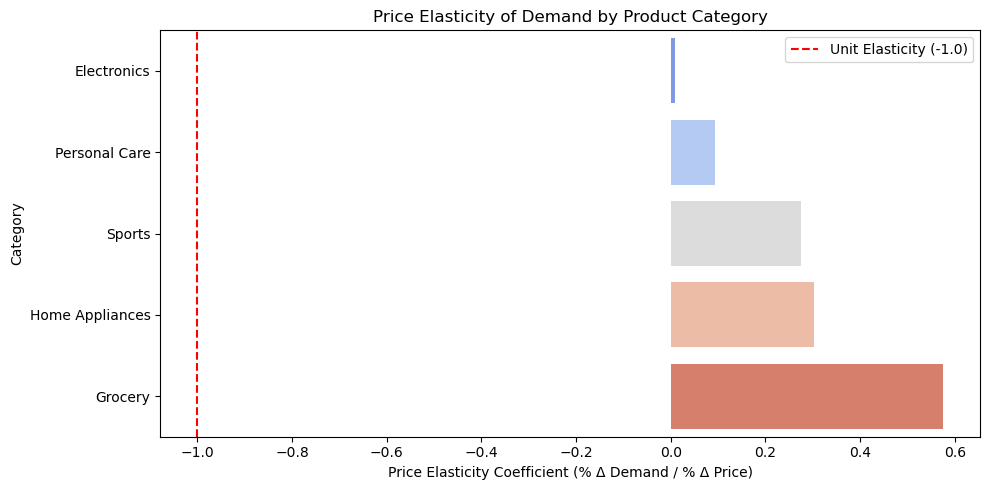

In [5]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=elasticity_results,
    x="Elasticity",
    y="Category",
    hue="Category",
    palette="coolwarm",
    legend=False
)

plt.axvline(x=-1.0, color="red", linestyle="--", label="Unit Elasticity (-1.0)")

plt.title("Price Elasticity of Demand by Product Category")
plt.xlabel("Price Elasticity Coefficient (% Δ Demand / % Δ Price)")
plt.ylabel("Category")
plt.legend()
plt.tight_layout()
plt.show()

Interpretation Note:
Elastic Demand ($E < -1.0$): High sensitivity to price changes (e.g., price increases lead to a proportionally larger drop in demand).
Inelastic Demand ($-1.0 < E < 0$): Low sensitivity to price changes (e.g., price increases lead to higher total revenue despite slight volume drops).